Using device: cuda
Classi nel Train Set -> Maligni (0): 147, Benigni (1): 399
Epoch 1/20 - Train Loss: 0.3299 | Val Loss: 0.3121 | Val F1: 0.8182 | Val AUC: 0.7803
Epoch 2/20 - Train Loss: 0.2421 | Val Loss: 0.3023 | Val F1: 0.8496 | Val AUC: 0.7728
Epoch 3/20 - Train Loss: 0.2119 | Val Loss: 0.2456 | Val F1: 0.8772 | Val AUC: 0.8630
Epoch 4/20 - Train Loss: 0.1735 | Val Loss: 0.2177 | Val F1: 0.9333 | Val AUC: 0.8922
Epoch 5/20 - Train Loss: 0.1521 | Val Loss: 0.2521 | Val F1: 0.8870 | Val AUC: 0.8847
Epoch 6/20 - Train Loss: 0.1199 | Val Loss: 0.2029 | Val F1: 0.8889 | Val AUC: 0.9081
Epoch 7/20 - Train Loss: 0.0989 | Val Loss: 0.2362 | Val F1: 0.9322 | Val AUC: 0.9023
Epoch 8/20 - Train Loss: 0.0728 | Val Loss: 0.2241 | Val F1: 0.9310 | Val AUC: 0.8981
Epoch 9/20 - Train Loss: 0.0559 | Val Loss: 0.2610 | Val F1: 0.9322 | Val AUC: 0.9206
Epoch 10/20 - Train Loss: 0.0506 | Val Loss: 0.1747 | Val F1: 0.9483 | Val AUC: 0.9557
Epoch 11/20 - Train Loss: 0.0478 | Val Loss: 0.1938 | Val F1:

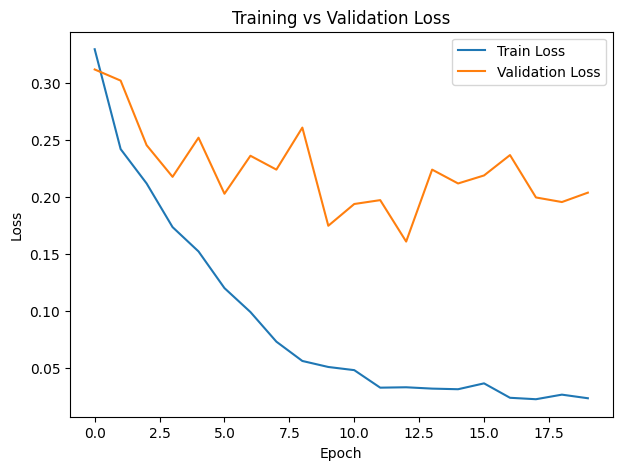


--- RISULTATI FINALI TEST SET RESNET18 (OTTIMIZZATI) ---
Accuracy:      0.8974
F1-Score:      0.9298 (Benign)
AUC-ROC:       0.8997
Sensitivity:   0.8095 (Malignant - Class 0)
Specificity:   0.9298 (Benign - Class 1)


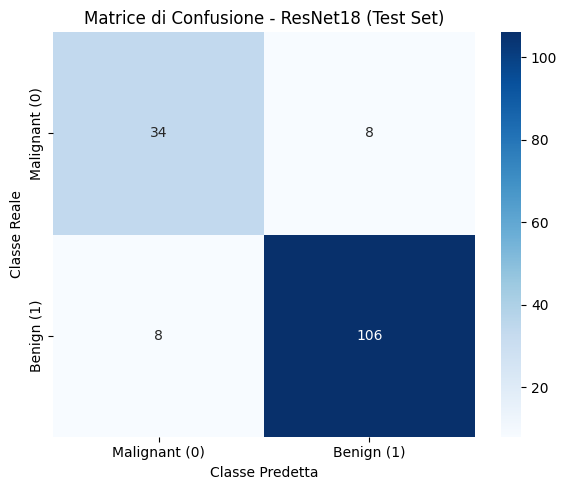


--- RISULTATI DETTAGLIATI SENSITIVITY ---
Sensitivity (malignant): 0.8095
Sensitivity (benign): 0.9298


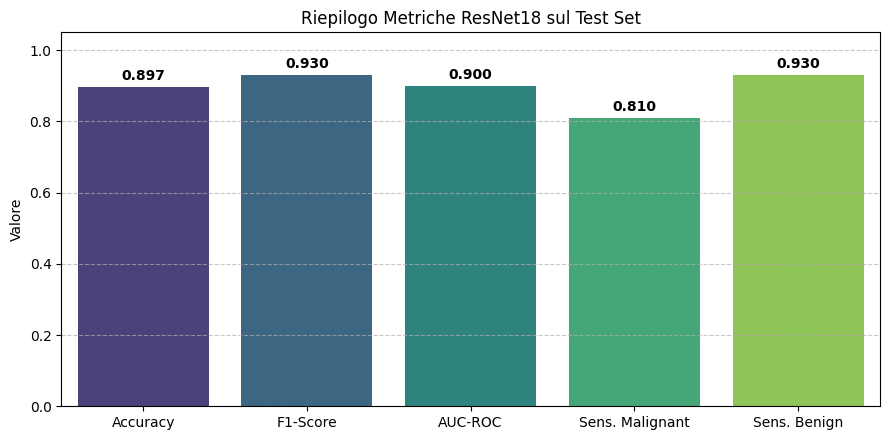

Totale immagini classificate erroneamente: 16 su 156


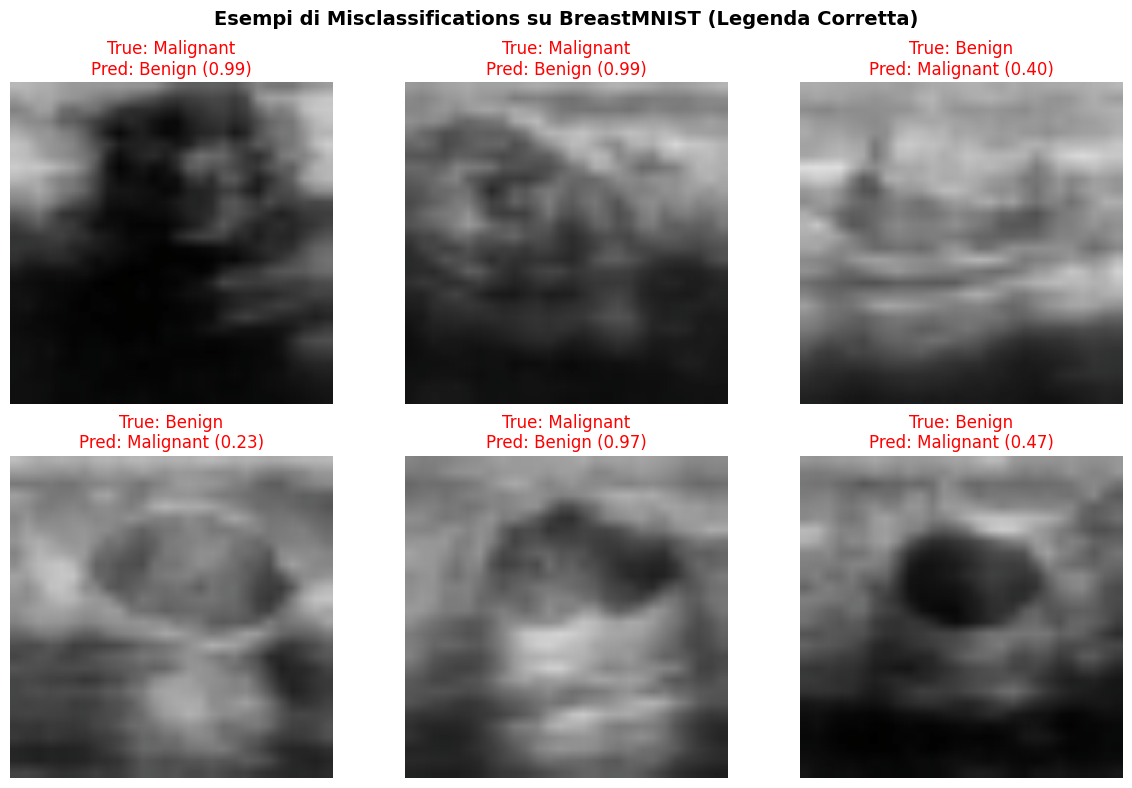

In [8]:
!pip install medmnist

import os
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import medmnist
from medmnist import INFO, Evaluator
import matplotlib.pyplot as plt

import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


# 1. Configurazione Device e Parametri
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

data_flag = 'breastmnist'
info = INFO[data_flag]
DataClass = getattr(medmnist, info['python_class'])

BATCH_SIZE = 32
NUM_EPOCHS = 20

# 2. Data Augmentation (Ottimizzato con parametri ImageNet)
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

train_dataset = DataClass(split='train', transform=train_transform, download=True, as_rgb=True)
val_dataset = DataClass(split='val', transform=val_test_transform, download=True, as_rgb=True)
test_dataset = DataClass(split='test', transform=val_test_transform, download=True, as_rgb=True)

train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 3. Sbilanciamento Classi (Classe 0: Maligno, Classe 1: Benigno)
train_labels = train_dataset.labels.flatten()
num_malignant = np.sum(train_labels == 0)
num_benign = np.sum(train_labels == 1)
print(f"Classi nel Train Set -> Maligni (0): {num_malignant}, Benigni (1): {num_benign}")

# Il pos_weight controlla il peso della classe positiva (1: Benigno)
pos_weight_val = torch.tensor([num_malignant / num_benign], dtype=torch.float).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_val)

# 4. Modello ResNet18 con Fine-Tuning Differenziato e Regolarizzazione Dropout
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# SBLOCCHIAMO TUTTI I LIVELLI (Full Fine-Tuning)
for param in model.parameters():
  param.requires_grad = True


# NUOVO CLASSIFICATORE
num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
nn.Dropout(0.3),
nn.Linear(num_ftrs, 1)
)
for param in model.fc.parameters():
  param.requires_grad = True


model = model.to(device)


# Usiamo un Learning Rate più basso per il Full Fine-Tuning (1e-4) per preservare i pesi appresi
optimizer = optim.AdamW(
model.parameters(),
lr=1e-4,
weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)


# 5. Loop di Training e Validazione con salvataggio del miglior stato
best_val_loss = float('inf')
best_model_wts = copy.deepcopy(model.state_dict())

train_losses = []
val_losses = []
val_f1s = []
val_aucs = []

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss = 0.0
    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device).float()

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader.dataset)
    scheduler.step()

    # Validazione
    model.eval()
    val_loss = 0.0
    val_targets_all = []
    val_preds_all = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device).float()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)

            probs = torch.sigmoid(outputs)
            val_targets_all.extend(targets.cpu().numpy())
            val_preds_all.extend(probs.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    val_preds_class = (np.array(val_preds_all) >= 0.5).astype(int)
    val_f1 = f1_score(val_targets_all, val_preds_class)
    val_auc = roc_auc_score(val_targets_all, val_preds_all)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_f1s.append(val_f1)
    val_aucs.append(val_auc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val F1: {val_f1:.4f} | Val AUC: {val_auc:.4f}")

    # Salvataggio del modello migliore basato su Validation Loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_wts = copy.deepcopy(model.state_dict())

# Ricarichiamo i pesi ottimali trovati
model.load_state_dict(best_model_wts)

plt.figure(figsize=(7,5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

# 6. Valutazione Finale sul Test Set
model.eval()
test_targets_all = []
test_preds_all = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        probs = torch.sigmoid(outputs)
        test_targets_all.extend(targets.numpy())
        test_preds_all.extend(probs.cpu().numpy())

test_targets_all = np.array(test_targets_all)
test_preds_all = np.array(test_preds_all)
test_preds_class = (test_preds_all >= 0.5).astype(int)

# Ricalcoliamo le metriche finali
acc = accuracy_score(test_targets_all, test_preds_class)
f1 = f1_score(test_targets_all, test_preds_class)
auc = roc_auc_score(test_targets_all, test_preds_all)

tn, fp, fn, tp = confusion_matrix(test_targets_all, test_preds_class).ravel()
sensitivity = tn / (tn + fp)  # Sensibilità sui maligni (classe 0)
specificity = tp / (tp + fn)  # Specificità sui benigni (classe 1)

print("\n--- RISULTATI FINALI TEST SET RESNET18 (OTTIMIZZATI) ---")
print(f"Accuracy:      {acc:.4f}")
print(f"F1-Score:      {f1:.4f} (Benign)")
print(f"AUC-ROC:       {auc:.4f}")
print(f"Sensitivity:   {sensitivity:.4f} (Malignant - Class 0)")
print(f"Specificity:   {specificity:.4f} (Benign - Class 1)")

"""### Grafici delle Prestazioni e Matrice di Confusione"""

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Matrice di Confusione con etichette corrette
cm = confusion_matrix(test_targets_all, test_preds_class)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant (0)', 'Benign (1)'],
            yticklabels=['Malignant (0)', 'Benign (1)'])
plt.title('Matrice di Confusione - ResNet18 (Test Set)')
plt.ylabel('Classe Reale')
plt.xlabel('Classe Predetta')
plt.tight_layout()
plt.show()

# 2. Calcolo della Sensitivity per entrambe le classi (come consigliato)
tn, fp, fn, tp = cm.ravel()

sensitivity_malignant = tn / (tn + fp)
sensitivity_benign = tp / (tp + fn)

print("\n--- RISULTATI DETTAGLIATI SENSITIVITY ---")
print(f'Sensitivity (malignant): {sensitivity_malignant:.4f}')
print(f'Sensitivity (benign): {sensitivity_benign:.4f}')

# 3. Grafico di confronto metriche aggiornato
metrics_name = ['Accuracy', 'F1-Score', 'AUC-ROC', 'Sens. Malignant', 'Sens. Benign']
metrics_val = [acc, f1, auc, sensitivity_malignant, sensitivity_benign]

plt.figure(figsize=(9, 4.5))
sns.barplot(x=metrics_name, y=metrics_val, palette='viridis', hue=metrics_name, legend=False)
plt.ylim(0, 1.05)
for i, val in enumerate(metrics_val):
    plt.text(i, val + 0.02, f"{val:.3f}", ha='center', fontweight='bold')
plt.title('Riepilogo Metriche ResNet18 sul Test Set')
plt.ylabel('Valore')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

"""### Analisi delle Errate Classificazioni (Misclassifications)

Visualizziamo alcune delle immagini ecografiche del test set che la ResNet18 ha fallito nel classificare correttamente.
"""

# Identifichiamo gli indici degli errori
misclassified_indices = np.where(test_preds_class.flatten() != test_targets_all.flatten())[0]
print(f"Totale immagini classificate erroneamente: {len(misclassified_indices)} su {len(test_targets_all)}")

# Funzione per mostrare alcune immagini errate con le corrette etichette
plt.figure(figsize=(12, 8))
num_to_show = min(6, len(misclassified_indices))

# Definiamo i vettori di media e deviazione standard per invertire la normalizzazione
mean_np = np.array([0.485, 0.456, 0.406])
std_np = np.array([0.229, 0.224, 0.225])

for idx, mis_idx in enumerate(misclassified_indices[:num_to_show]):
    # Recuperiamo l'immagine originale direttamente dal test dataset
    img, label = test_dataset[mis_idx]

    # Convertiamo il tensore normalizzato in un'immagine visualizzabile tramite denormalizzazione corretta
    img_np = img.permute(1, 2, 0).numpy()
    img_np = (img_np * std_np) + mean_np
    img_np = np.clip(img_np, 0, 1)

    pred_label = test_preds_class[mis_idx][0]
    prob = test_preds_all[mis_idx][0]

    plt.subplot(2, 3, idx + 1)
    plt.imshow(img_np)

    # Classe 0: Maligno, Classe 1: Benigno
    real_str = "Benign" if label[0] == 1 else "Malignant"
    pred_str = "Benign" if pred_label == 1 else "Malignant"

    plt.title(f"True: {real_str}\nPred: {pred_str} ({prob:.2f})", color='red')
    plt.axis('off')

plt.suptitle("Esempi di Misclassifications su BreastMNIST (Legenda Corretta)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()